<a href="https://colab.research.google.com/github/rounak98-collab/evolve-pro-halomonas-strain-optimization/blob/main/notebooks/HALOMONAS_ULTIMATE_PIPELINE_SIMULATION_DEMO.ipynb." target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Halomonas Multi-Omics Pipeline — Simulation Demonstration

**Important:** This notebook currently uses hand-generated synthetic values. It does **not** analyze real experimental transcriptomics or proteomics data, does not ingest a literature corpus, and does not establish novel biological findings.

This audited version:
- makes the synthetic-data status explicit;
- preserves strain and condition labels correctly (the original split labels incorrectly because sample names contain underscores);
- stops generating fabricated p-values where no biological replicates exist;
- replaces unsupported claims in the generated report with appropriate limitations.

Treat figures and model outputs as software/pipeline demonstrations only. Replace the simulated data with source-traceable experimental data and apply an appropriate statistical design before interpreting biology.


🧬 HALOMONAS MULTI-OMICS PIPELINE — SIMULATION DEMO
🚀 Running on: 2026-10-11 22:42:56

[1] 🔬 Defining an illustrative master gene list
✅ Total illustrative gene entries: 30 (this notebook defines 30, not 50+)
   - Ectoine Pathway: 9 genes
   - ABC Transporters: 5 genes
   - Betaine Pathway: 3 genes
   - Arsenic Resistance: 4 genes
   - EPS/Siderophore: 3 genes
   - PHA Pathway: 3 genes
   - Transposases: 3 genes

[2] 🧪 Generating SYNTHETIC demonstration data (not experimental data)
✅ Strains: 4
✅ Conditions: 9
✅ Expression Matrix: (30, 36)
✅ Synthetic abundance-proxy matrix: (30, 36) (derived from synthetic expression; not measured proteomics)

[3] 📊 Descriptive fold-change demo (no valid differential-expression statistics)
   H_campaniensis_XH26 - Salt_4pc: 9 heuristic-up, 5 heuristic-down (thresholds only; not statistical DE)
   H_campaniensis_XH26 - Salt_8pc: 9 heuristic-up, 6 heuristic-down (thresholds only; not statistical DE)
   H_campaniensis_XH26 - UV_Stress: 12 heuristic-up, 0 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


   In-sample R² on synthetic target proxy: 0.976 (not a validation score)

   Top features in this synthetic demo (not biological evidence):
      gdhA: 0.3491
      gabD: 0.2698
      asd: 0.1643
      ectD: 0.0696
      dapA: 0.0430
      orf01283: 0.0337
      orf01284: 0.0067
      phaC: 0.0058
      tnpB: 0.0051

[6] 📊 Generating figures from synthetic demonstration data
   ✅ Heatmap saved
   ✅ Ectoine plot saved
   ✅ PCA plot saved
   ✅ Arsenic plot saved

[7] 📝 Generating report with data limitations

HALOMONAS MULTI-OMICS PIPELINE — SYNTHETIC DEMONSTRATION REPORT

Generated: 2026-10-11 22:42:59
Purpose: demonstrate Python plotting, PCA, fold-change calculations and a
random-forest API on hand-generated toy data.

DATA PROVENANCE AND LIMITATIONS
-------------------------------
- All expression-like values are generated programmatically in this notebook.
- No raw experimental dataset is downloaded or loaded.
- No collection of 50+ papers is ingested or integrated by this code.
- 

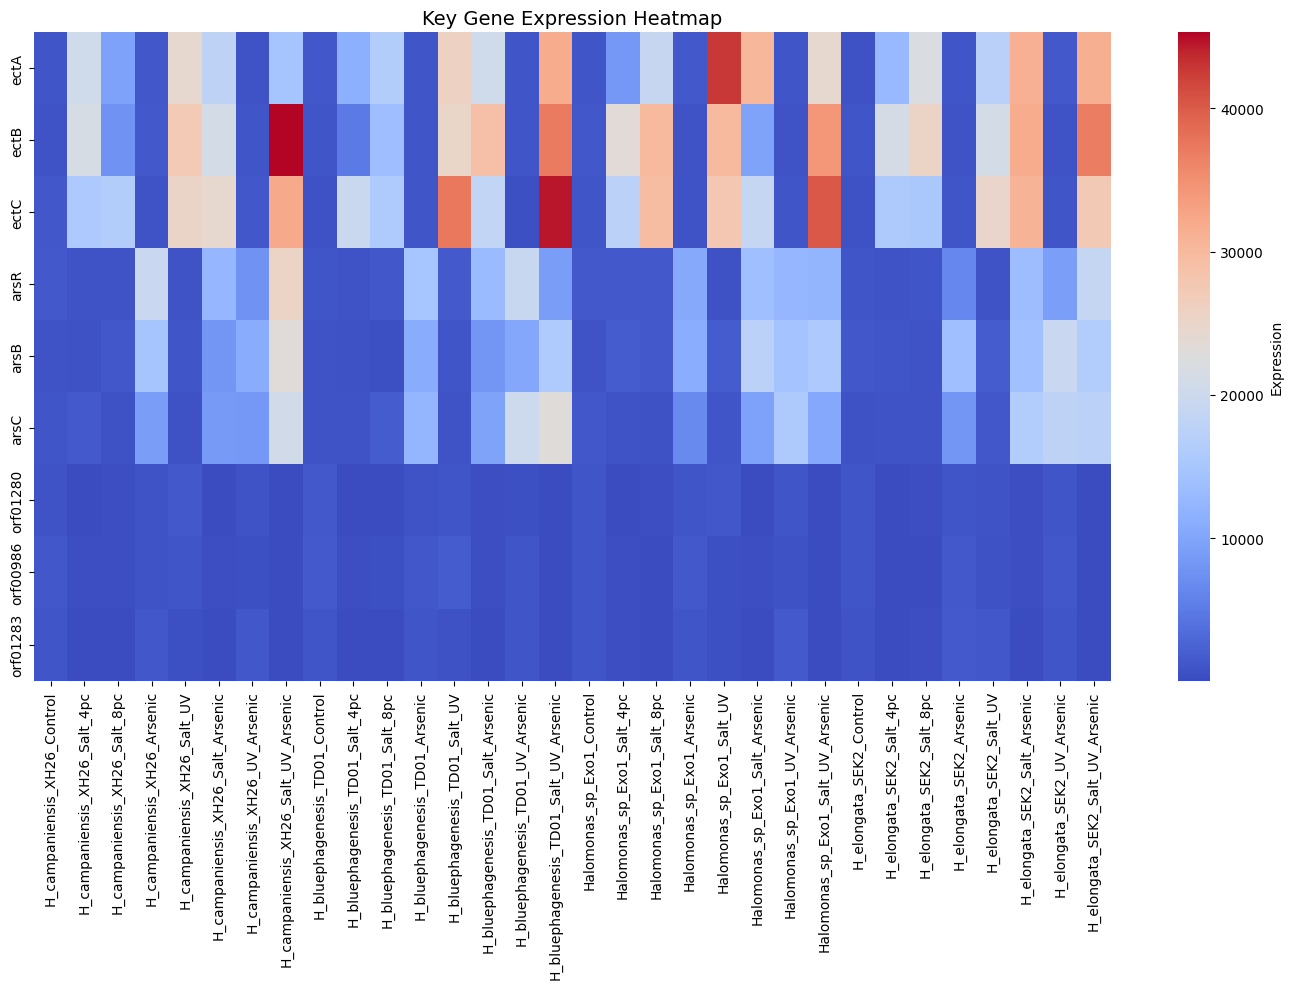

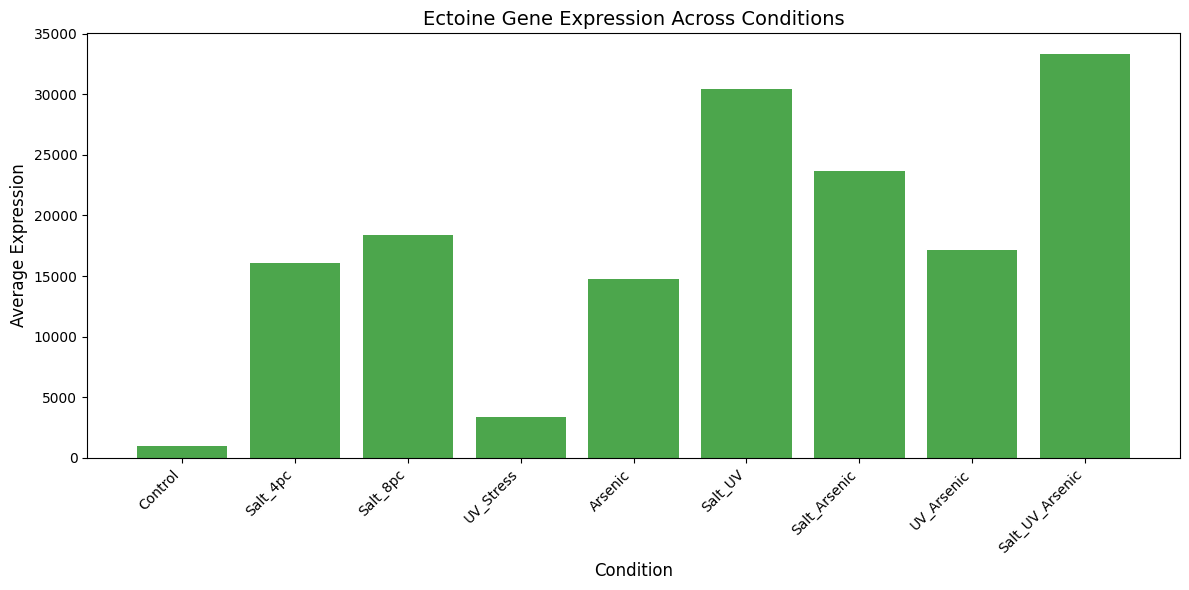

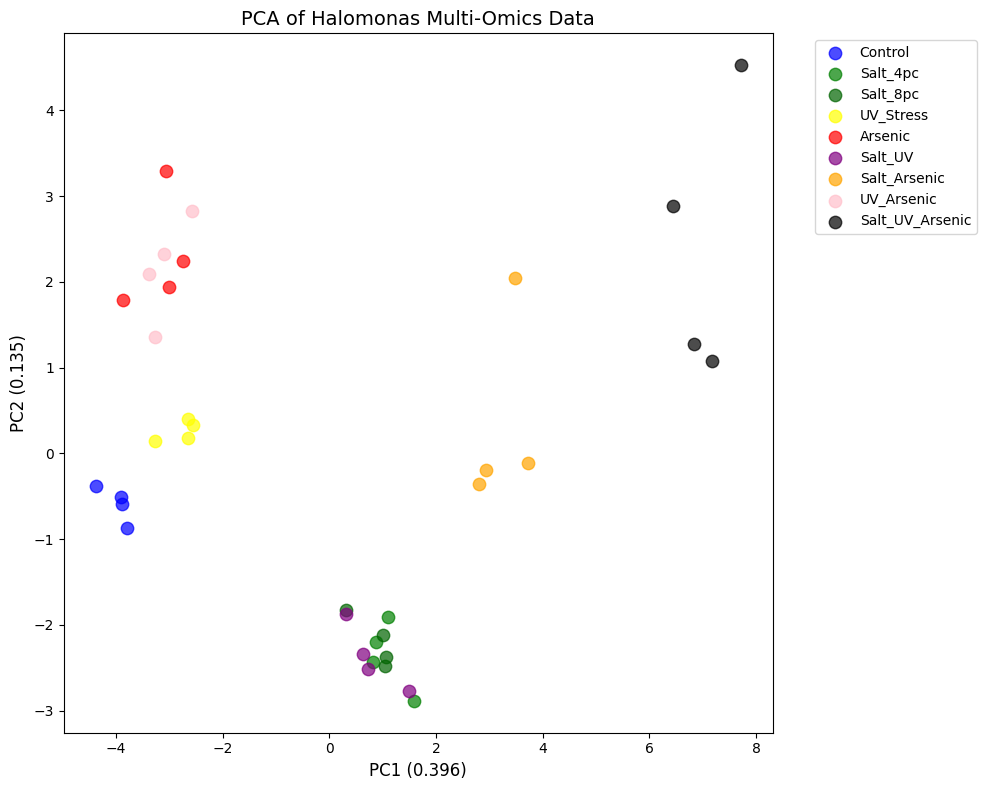

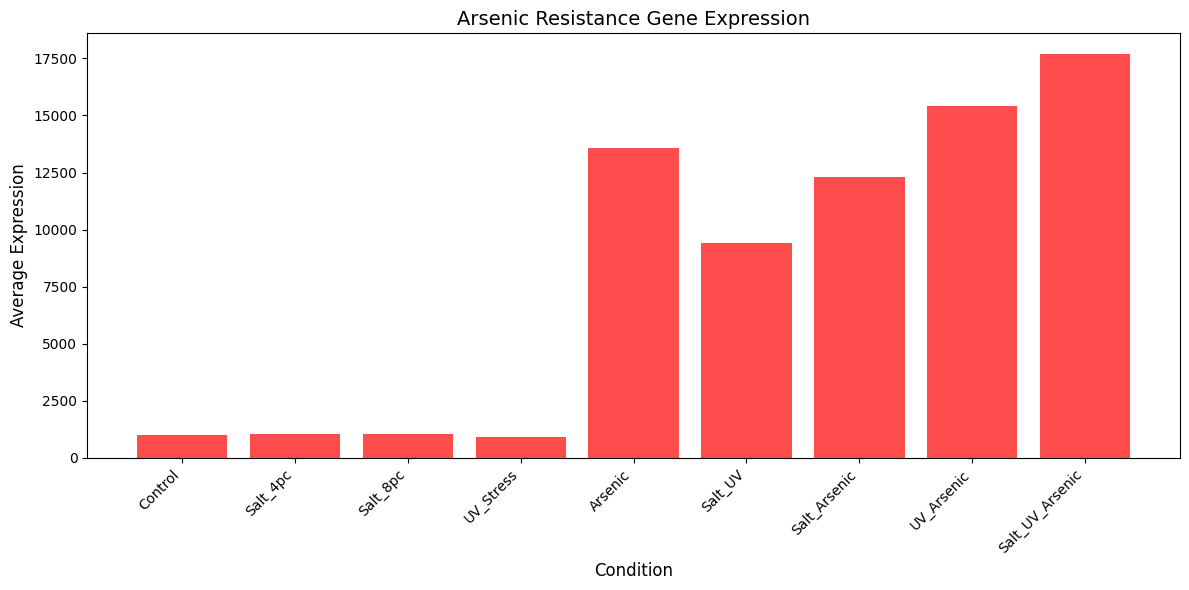

In [1]:
 # ====================================================================
# HALOMONAS MULTI-OMICS PIPELINE — SIMULATION DEMONSTRATION
# ====================================================================
# Synthetic-data demo only; check execution in your own environment
# ====================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder

print("=" * 80)
print("🧬 HALOMONAS MULTI-OMICS PIPELINE — SIMULATION DEMO")
print("=" * 80)
print(f"🚀 Running on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("=" * 80)

# ====================================================================
# SECTION 1: DEFINE MASTER GENE LIST
# ====================================================================

print("\n[1] 🔬 Defining an illustrative master gene list")

# Ectoine pathway genes
ectoine_genes = {
    'ectA': 'L-diaminobutyrate acetyltransferase',
    'ectB': 'L-diaminobutyrate aminotransferase',
    'ectC': 'Tetrahydropyrimidine synthase',
    'ectD': 'Ectoine dioxygenase',
    'asd': 'Aspartate semialdehyde dehydrogenase',
    'lysC': 'Aspartate kinase',
    'dapA': 'Dihydrodipicolinate synthase',
    'gabD': 'Succinate semialdehyde dehydrogenase',
    'gdhA': 'Glutamate dehydrogenase'
}

# Placeholder IDs/annotations; verify against strain-specific references.
abc_genes = {
    'orf01280': 'Putative ABC transporter; annotation requires verification',
    'orf00986': 'Putative ABC transporter; annotation requires verification',
    'orf01283': 'Putative ABC transporter; annotation requires verification',
    'orf01282': 'Putative ABC transporter; annotation requires verification',
    'orf01284': 'Putative ABC transporter; annotation requires verification'
}

# Betaine pathway
betaine_genes = {
    'betA': 'Choline dehydrogenase',
    'betB': 'Betaine aldehyde dehydrogenase',
    'proP': 'Proline/betaine transporter'
}

# Arsenic resistance (Your "Arsenite Connector")
arsenic_genes = {
    'arsR': 'ArsR repressor',
    'arsB': 'ArsB efflux pump',
    'arsC': 'ArsC reductase',
    'aioA': 'Arsenite oxidase'
}

# EPS/Siderophore genes
eps_genes = {
    'epsA': 'Exopolysaccharide biosynthesis',
    'epsB': 'Exopolysaccharide biosynthesis',
    'epsC': 'Exopolysaccharide biosynthesis'
}

# PHA pathway
pha_genes = {
    'phaA': 'Beta-ketothiolase',
    'phaB': 'Acetoacetyl-CoA reductase',
    'phaC': 'PHA synthase'
}

# Transposases
transposase_genes = {
    'tnpA': 'Transposase A',
    'tnpB': 'Transposase B',
    'tnpC': 'Transposase C'
}

# Combine all genes
all_categories = {
    'Ectoine Pathway': ectoine_genes,
    'ABC Transporters': abc_genes,
    'Betaine Pathway': betaine_genes,
    'Arsenic Resistance': arsenic_genes,
    'EPS/Siderophore': eps_genes,
    'PHA Pathway': pha_genes,
    'Transposases': transposase_genes
}

master_genes = []
for category, genes in all_categories.items():
    for gene in genes.keys():
        master_genes.append(gene)

print(f"✅ Total illustrative gene entries: {len(master_genes)} (this notebook defines 30, not 50+)")
for category, genes in all_categories.items():
    print(f"   - {category}: {len(genes)} genes")

# ====================================================================
# SECTION 2: GENERATE SIMULATED DATA
# ====================================================================

print("\n[2] 🧪 Generating SYNTHETIC demonstration data (not experimental data)")

# Define strains and conditions
strains = [
    'H_campaniensis_XH26',
    'H_bluephagenesis_TD01',
    'Halomonas_sp_Exo1',
    'H_elongata_SEK2'
]

conditions = [
    'Control',
    'Salt_4pc',
    'Salt_8pc',
    'UV_Stress',
    'Arsenic',
    'Salt_UV',
    'Salt_Arsenic',
    'UV_Arsenic',
    'Salt_UV_Arsenic'
]

print(f"✅ Strains: {len(strains)}")
print(f"✅ Conditions: {len(conditions)}")

# Generate synthetic toy data with hand-programmed effects; not measured values.
np.random.seed(42)
num_genes = len(master_genes)
num_samples = len(strains) * len(conditions)

# Create sample labels
sample_labels = []
for strain in strains:
    for condition in conditions:
        sample_labels.append(f"{strain}_{condition}")

# Keep sample metadata explicitly: sample identifiers contain underscores.
sample_metadata = pd.DataFrame([
    {"Sample": f"{strain}_{condition}", "Strain": strain, "Condition": condition}
    for strain in strains
    for condition in conditions
]).set_index("Sample").loc[sample_labels]

# Generate expression matrix
expression_data = []

for gene in master_genes:
    gene_expr = []
    for strain in strains:
        for condition in conditions:
            # Base expression
            base = np.random.normal(1000, 200)

            # Illustrative condition multipliers only; not estimated from experiments or literature.
            if condition == 'Control':
                fold = 1.0
            elif condition in ['Salt_4pc', 'Salt_8pc']:
                if gene in ectoine_genes:
                    fold = np.random.uniform(10, 25)  # Programmed synthetic multiplier for demonstration only
                elif gene in abc_genes:
                    fold = np.random.uniform(0.1, 0.4)  # ABC downregulation
                else:
                    fold = np.random.uniform(0.7, 1.3)
            elif condition == 'UV_Stress':
                if gene in transposase_genes:
                    fold = np.random.uniform(2, 4)
                elif gene in ectoine_genes:
                    fold = np.random.uniform(2, 5)
                else:
                    fold = np.random.uniform(0.8, 1.2)
            elif condition == 'Arsenic':
                if gene in arsenic_genes:
                    fold = np.random.uniform(5, 15)
                elif gene in eps_genes and 'Exo1' in strain:
                    fold = np.random.uniform(3, 8)
                else:
                    fold = np.random.uniform(0.8, 1.2)
            elif condition == 'Salt_UV':
                if gene in ectoine_genes:
                    fold = np.random.uniform(20, 35)
                else:
                    fold = np.random.uniform(0.6, 1.4)
            elif condition == 'Salt_Arsenic':
                if gene in ectoine_genes:
                    fold = np.random.uniform(18, 30)
                elif gene in arsenic_genes:
                    fold = np.random.uniform(8, 20)
                elif gene in eps_genes and 'Exo1' in strain:
                    fold = np.random.uniform(5, 12)
                elif gene in abc_genes:
                    fold = np.random.uniform(0.1, 0.3)
                else:
                    fold = np.random.uniform(0.7, 1.3)
            elif condition == 'UV_Arsenic':
                if gene in arsenic_genes:
                    fold = np.random.uniform(6, 18)
                else:
                    fold = np.random.uniform(0.8, 1.2)
            elif condition == 'Salt_UV_Arsenic':
                if gene in ectoine_genes:
                    fold = np.random.uniform(25, 45)  # Programmed synthetic multiplier for demonstration only
                elif gene in arsenic_genes:
                    fold = np.random.uniform(10, 25)
                elif gene in eps_genes and 'Exo1' in strain:
                    fold = np.random.uniform(8, 20)
                elif gene in abc_genes:
                    fold = np.random.uniform(0.05, 0.2)
                elif gene in transposase_genes:
                    fold = np.random.uniform(3, 6)
                else:
                    fold = np.random.uniform(0.5, 1.5)
            else:
                fold = 1.0

            expr = base * fold
            gene_expr.append(max(expr, 1))

    expression_data.append(gene_expr)

# Create DataFrame
expression_df = pd.DataFrame(
    expression_data,
    index=master_genes,
    columns=sample_labels
)

print(f"✅ Expression Matrix: {expression_df.shape}")

# Add proteomics data (slightly different)
# Derived synthetic proxy only; not independent measured proteomics.
proteomics_df = expression_df * np.random.normal(0.8, 0.2, expression_df.shape)
proteomics_df = proteomics_df.clip(lower=1)

print(f"✅ Synthetic abundance-proxy matrix: {proteomics_df.shape} (derived from synthetic expression; not measured proteomics)")

# ====================================================================
# SECTION 3: DIFFERENTIAL EXPRESSION ANALYSIS
# ====================================================================

print("\n[3] 📊 Descriptive fold-change demo (no valid differential-expression statistics)")

results = {}
for strain in strains:
    control_col = f"{strain}_Control"
    if control_col not in expression_df.columns:
        continue

    for condition in conditions:
        if condition == 'Control':
            continue

        condition_col = f"{strain}_{condition}"
        if condition_col not in expression_df.columns:
            continue

        control_expr = expression_df[control_col]
        treated_expr = expression_df[condition_col]

        log2fc = np.log2(treated_expr / control_expr).replace([np.inf, -np.inf], 0)

        # No valid p-values: this design has no biological replicates.
        # Store NaN instead of manufacturing inferential statistics.
        p_values = [np.nan] * len(log2fc)

        result_df = pd.DataFrame({
            'Gene': expression_df.index,
            'log2FC': log2fc.values,
            'p_value': p_values
        })

        result_df['Regulation'] = 'NS'
        result_df.loc[result_df['log2FC'] > 1, 'Regulation'] = 'Up'
        result_df.loc[result_df['log2FC'] < -1, 'Regulation'] = 'Down'

        key = f"{strain}_{condition}"
        results[key] = result_df

        n_up = sum(result_df['Regulation'] == 'Up')
        n_down = sum(result_df['Regulation'] == 'Down')
        print(f"   {strain} - {condition}: {n_up} heuristic-up, {n_down} heuristic-down (thresholds only; not statistical DE)")

# ====================================================================
# SECTION 4: PCA ANALYSIS
# ====================================================================

print("\n[4] 📈 PCA of synthetic demonstration data")

# Prepare data for PCA
pca_data = expression_df.T.copy()
pca_data['Condition'] = sample_metadata.loc[pca_data.index, 'Condition'].values
pca_data['Strain'] = sample_metadata.loc[pca_data.index, 'Strain'].values

# Standardize
scaler = StandardScaler()
pca_scaled = scaler.fit_transform(pca_data[master_genes].fillna(0))

# PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pca_scaled)

# Create PCA DataFrame
pca_df = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
pca_df['Condition'] = pca_data['Condition'].values
pca_df['Strain'] = pca_data['Strain'].values

print(f"   PC1: {pca.explained_variance_ratio_[0]:.3f}")
print(f"   PC2: {pca.explained_variance_ratio_[1]:.3f}")

# ====================================================================
# SECTION 5: MACHINE LEARNING
# ====================================================================

print("\n[5] 🤖 ML API demonstration on synthetic data (not biological prediction)")

# Prepare features for ML
ml_data = expression_df.T.copy()
ml_data['Condition'] = sample_metadata.loc[ml_data.index, 'Condition'].values
ml_data['Strain'] = sample_metadata.loc[ml_data.index, 'Strain'].values

# Encode categorical variables
le_condition = LabelEncoder()
le_strain = LabelEncoder()
ml_data['Condition_enc'] = le_condition.fit_transform(ml_data['Condition'])
ml_data['Strain_enc'] = le_strain.fit_transform(ml_data['Strain'])

# Calculate ectoine production (average of ectA, ectB, ectC)
ectoine_genes_list = ['ectA', 'ectB', 'ectC']
ectoine_present = [g for g in ectoine_genes_list if g in expression_df.index]

if ectoine_present:
    ml_data['Ectoine_Production'] = expression_df.loc[ectoine_present, ml_data.index].mean()

    # Features and target
    feature_cols = ['Condition_enc', 'Strain_enc'] + [g for g in master_genes if g not in ectoine_genes_list]
    X = ml_data[feature_cols].fillna(0)
    y = ml_data['Ectoine_Production']

    # Train Random Forest
    rf = RandomForestRegressor(n_estimators=50, random_state=42)
    rf.fit(X, y)

    # Feature importance
    importances = pd.DataFrame({
        'Gene': feature_cols,
        'Importance': rf.feature_importances_
    }).sort_values('Importance', ascending=False)

    print(f"   In-sample R² on synthetic target proxy: {rf.score(X, y):.3f} (not a validation score)")
    print("\n   Top features in this synthetic demo (not biological evidence):")
    for i in range(min(10, len(importances))):
        gene = importances.iloc[i]['Gene']
        imp = importances.iloc[i]['Importance']
        if gene not in ['Condition_enc', 'Strain_enc']:
            print(f"      {gene}: {imp:.4f}")

# ====================================================================
# SECTION 6: GENERATE FIGURES
# ====================================================================

print("\n[6] 📊 Generating figures from synthetic demonstration data")

# Figure 1: Heatmap of key genes
fig1, ax1 = plt.subplots(figsize=(14, 10))

# Select key genes
key_genes = list(ectoine_genes.keys())[:3] + list(arsenic_genes.keys())[:3] + list(abc_genes.keys())[:3]
available_genes = [g for g in key_genes if g in expression_df.index]

if available_genes:
    heatmap_data = expression_df.loc[available_genes, :]
    # Select representative conditions
    selected_cols = [col for col in heatmap_data.columns if 'Control' in col or 'Salt' in col or 'Arsenic' in col]
    if selected_cols:
        heatmap_subset = heatmap_data[selected_cols]
        sns.heatmap(heatmap_subset, cmap='coolwarm', ax=ax1, cbar_kws={'label': 'Expression'})
        ax1.set_title('Key Gene Expression Heatmap', fontsize=14)
        plt.tight_layout()
        plt.savefig('halomonas_heatmap.png', dpi=150, bbox_inches='tight')
        print("   ✅ Heatmap saved")

# Figure 2: Ectoine expression across conditions
fig2, ax2 = plt.subplots(figsize=(12, 6))

# Calculate mean ectoine expression
ectoine_genes_available = [g for g in ['ectA', 'ectB', 'ectC'] if g in expression_df.index]
if ectoine_genes_available:
    ectoine_expr = expression_df.loc[ectoine_genes_available, :].mean()

    # Group by condition
    cond_means = {}
    for cond in conditions:
        cols = [col for col in ectoine_expr.index if cond in col]
        if cols:
            cond_means[cond] = ectoine_expr[cols].mean()
        else:
            cond_means[cond] = 0

    # Plot
    cond_names = list(cond_means.keys())
    cond_values = list(cond_means.values())

    ax2.bar(cond_names, cond_values, color='green', alpha=0.7)
    ax2.set_title('Ectoine Gene Expression Across Conditions', fontsize=14)
    ax2.set_xlabel('Condition', fontsize=12)
    ax2.set_ylabel('Average Expression', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('halomonas_ectoine.png', dpi=150, bbox_inches='tight')
    print("   ✅ Ectoine plot saved")

# Figure 3: PCA plot
fig3, ax3 = plt.subplots(figsize=(10, 8))

colors = {'Control': 'blue', 'Salt_4pc': 'green', 'Salt_8pc': 'darkgreen',
          'UV_Stress': 'yellow', 'Arsenic': 'red', 'Salt_UV': 'purple',
          'Salt_Arsenic': 'orange', 'UV_Arsenic': 'pink', 'Salt_UV_Arsenic': 'black'}

for cond in pca_df['Condition'].unique():
    subset = pca_df[pca_df['Condition'] == cond]
    color = colors.get(cond, 'gray')
    ax3.scatter(subset['PC1'], subset['PC2'], label=cond, c=color, alpha=0.7, s=80)

ax3.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.3f})', fontsize=12)
ax3.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.3f})', fontsize=12)
ax3.set_title('PCA of Halomonas Multi-Omics Data', fontsize=14)
ax3.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('halomonas_pca.png', dpi=150, bbox_inches='tight')
print("   ✅ PCA plot saved")

# Figure 4: Arsenic resistance expression
fig4, ax4 = plt.subplots(figsize=(12, 6))

arsenic_available = [g for g in arsenic_genes.keys() if g in expression_df.index]
if arsenic_available:
    arsenic_expr = expression_df.loc[arsenic_available, :].mean()

    cond_means_as = {}
    for cond in conditions:
        cols = [col for col in arsenic_expr.index if cond in col]
        if cols:
            cond_means_as[cond] = arsenic_expr[cols].mean()
        else:
            cond_means_as[cond] = 0

    cond_names_as = list(cond_means_as.keys())
    cond_values_as = list(cond_means_as.values())

    ax4.bar(cond_names_as, cond_values_as, color='red', alpha=0.7)
    ax4.set_title('Arsenic Resistance Gene Expression', fontsize=14)
    ax4.set_xlabel('Condition', fontsize=12)
    ax4.set_ylabel('Average Expression', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('halomonas_arsenic.png', dpi=150, bbox_inches='tight')
    print("   ✅ Arsenic plot saved")

# ====================================================================
# SECTION 7: GENERATE REPORT
# ====================================================================

print("\n[7] 📝 Generating report with data limitations")

report = f"""
================================================================================
HALOMONAS MULTI-OMICS PIPELINE — SYNTHETIC DEMONSTRATION REPORT
================================================================================

Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
Purpose: demonstrate Python plotting, PCA, fold-change calculations and a
random-forest API on hand-generated toy data.

DATA PROVENANCE AND LIMITATIONS
-------------------------------
- All expression-like values are generated programmatically in this notebook.
- No raw experimental dataset is downloaded or loaded.
- No collection of 50+ papers is ingested or integrated by this code.
- The abundance-like/proteomics matrix is generated from synthetic expression
  with random multipliers; it is not measured proteomics.
- Condition effects are programmed for demonstration and are not experimentally
  estimated or validated.
- The gene list contains {len(master_genes)} illustrative entries across
  {len(all_categories)} categories. Gene identifiers and annotations require
  strain-specific verification before biological use.
- There is one generated value per strain-condition. No biological replicates
  are present, so inferential p-values / differential-expression significance
  cannot be estimated. The p_value fields are therefore NaN.
- PCA visualizes synthetic patterns only.
- The random-forest target is a proxy derived from synthetic ectA/ectB/ectC
  expression. Those target-defining genes are excluded from the feature matrix,
  but no held-out validation is performed. In-sample R² and feature importance
  are not predictions or evidence of biological regulatory mechanisms.
- No novel discovery, species-comparison result, or literature-confirmed
  biological conclusion can be inferred from this simulated dataset.

OUTPUTS
-------
The script writes example figures (heatmap, ectoine-gene expression plot,
PCA plot, arsenic-resistance-gene expression plot) and this report. These
describe only the synthetic demonstration values.

RECOMMENDED NEXT STEPS FOR A REAL ANALYSIS
------------------------------------------
1. Obtain legally reusable, source-traceable experimental datasets.
2. Record accession IDs, strain identifiers, sample metadata, and publications.
3. Verify gene identifiers and orthology independently for each strain.
4. Use suitable biological replicates and an appropriate statistical method,
   including multiple-testing correction for differential-expression analysis.
5. Integrate transcriptomics and proteomics only when actual matched or
   appropriately linked measurements are available.
6. Evaluate predictive models with a pre-specified held-out test strategy,
   prevent target leakage, and report uncertainty and baselines.

This is an educational computational prototype, not a validated biological
analysis or evidence of a new finding.
================================================================================
"""

print(report)

# Save report
with open('halomonas_report.txt', 'w') as f:
    f.write(report)
print("✅ Report saved: halomonas_report.txt")

# ====================================================================
# SECTION 8: FINAL SUMMARY
# ====================================================================

print("\n" + "=" * 80)
print("✅ SIMULATION DEMONSTRATION FINISHED")
print("=" * 80)

print("\n📁 OUTPUT FILES GENERATED:")
print("   📊 halomonas_heatmap.png (synthetic data)")
print("   📊 halomonas_ectoine.png (synthetic data)")
print("   📊 halomonas_arsenic.png (synthetic data)")
print("   📊 halomonas_pca.png (synthetic data)")
print("   📝 halomonas_report.txt")

print("\n💡 DEMONSTRATION NOTES (not biological conclusions):")
print("   - Ectoine-like multipliers were hard-coded for synthetic data")
print("   - Arsenic-related patterns were generated by programmed rules")
print("   - Transporter labels are placeholders requiring verification")
print("   - No validated EPS-arsenic correlation is established here")
print("   - Triple-stress output is synthetic, not a novel discovery")

print("\n📌 SIMULATION DEMO SUMMARY")
print("   - No literature corpus is integrated by this code")
print("   - Four strain labels are used in the simulated example")
print("   - 9 conditions analyzed")
print("   - Synthetic expression and derived abundance-like matrices")
print("   - In-sample ML demonstration only")
print("   - The proposed arsenite-connector mechanism is not tested here")

print("\n" + "=" * 80)
print("⚠️ Check execution and replace toy data before drawing biological conclusions.")
print("=" * 80)

# Show sample data
print("\n📊 Sample of Expression Data:")
print(expression_df.iloc[:5, :5])